In [1]:
# --- Make project imports work no matter where the notebook runs from ---
from pathlib import Path
import sys
import os

def find_project_root():
    here = Path.cwd()
    # Prefer a directory that has both 'utils' and 'models'
    for p in [here, *here.parents]:
        if (p / "utils").exists() and (p / "models").exists():
            return p
    # Fallback: look for common markers (git, requirements, pyproject)
    for p in [here, *here.parents]:
        if any((p / m).exists() for m in (".git", "requirements.txt", "pyproject.toml")):
            return p
    return here  # last resort

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root set to:", PROJECT_ROOT)

# Optional: nice for iterative development
%load_ext autoreload
%autoreload 2


import matplotlib.pyplot as plt
import torch
import numpy as np
import torch.nn as nn
import pandas as pd
import contextlib
import plotly.graph_objects as go
from torch.cuda.amp import autocast, GradScaler

from utils.reproducibility_utils import seed_everything
from utils.data_loading import load_data, load_test_data, feature_names
from utils.WeightedL1Loss import WeightedHybridLoss
from utils.LDS_FocalR_Loss import EnhancedLDS_FocalR_Loss
from utils.kaggle_metric import score

from models.lstm import LSTMModel
from models.gru import GRUModel

# Set the plotting style for better-looking visualizations
plt.style.available
plt.style.use('seaborn-v0_8')

Project root set to: /home/mdesouky/workspace/mait_g2_drift_challenge


In [2]:
CONFIG = {
    # PATHS
    'TRAIN_PATH': "../datasets_challenge/train",
    'TEST_PATH': "../datasets_challenge/test",
    'DIST_CSV': "../datasets_challenge/sideSlip_distribution.csv",
    'CHECKPOINT_NAME': "best_model.pth",
    'SUBMISSION_CSV': "predictions.csv",
    
    # REPRODUCIBILITY
    'SEED': 42,
    
    # DATA LOADING
    'TRAIN_RATIO': 0.8,
    'BATCH_SIZE': 256,
    'SEQUENCE_LENGTH': 20,
    'THRESHOLD': True,
    'THRESHOLD_VALUE': 3.0,
    'THRESHOLD_COLUMN': "vxCG",
    'COLUMNS_TO_DROP': ["sideSlip", "vyCG", "time", "longitude", "latitude"],
    'TARGET': "sideSlip",
    'SCALING': True,
    
    # MODEL ARCHITECTURE 
    'MODEL_TYPE': 'LSTM',
    'RNN_UNITS': 256,          
    'FC_UNITS': 256,        
    'NUM_LAYERS': 4,           
    'DROPOUT': [0.2, 0.15, 0.1], 
    'USE_BATCH_NORM': True,
    
   
    'LOSS_TYPE': 'WeightedHybrid',  # 'WeightedHybrid' or 'LDS_FocalR'
    'LOSS_THRESHOLDS': (0.1, 0.4),
    'LOSS_WEIGHTS': (1.0, 2.0, 4.0),
    'USE_HUBER': True,
    'HUBER_BETA': 0.1,
    
    # OPTIMIZER 
    'LEARNING_RATE': 1e-3,     
    'WEIGHT_DECAY': 5e-4,
    'BETAS': (0.9, 0.999),
    'MAX_GRAD_NORM': 1.0,     
    
    # SCHEDULER
    'SCHEDULER_T_MAX': 300,     #
    'SCHEDULER_ETA_MIN': 1e-6,
    
    # TRAINING 
    'NUM_EPOCHS': 300,         
    'EARLY_STOP_PATIENCE': 300, 
    'USE_AMP': True,
    'EMA_DECAY': 0.995,        
    
    # CHALLENGE CONSTRAINTS
    'MANY_SHOT_CONSTRAINT': 0.2,
    'FEW_SHOT_TARGET': 0.3,
    
    # VISUALIZATION
    'FIG_SIZE': (14, 8),
    'PLOTLY_WIDTH': 1200,
    'PLOTLY_HEIGHT': 500,
}

print("="*80)
print("CONFIGURATION LOADED")
print("="*80)
print(f"Model: {CONFIG['MODEL_TYPE']} | RNN Units: {CONFIG['RNN_UNITS']} | Layers: {CONFIG['NUM_LAYERS']}")
print(f"Loss: {CONFIG['LOSS_TYPE']} | Batch Size: {CONFIG['BATCH_SIZE']}")
print(f"LR: {CONFIG['LEARNING_RATE']:.1e} | Epochs: {CONFIG['NUM_EPOCHS']} | EMA Decay: {CONFIG['EMA_DECAY']}")
print(f"Early Stop Patience: {CONFIG['EARLY_STOP_PATIENCE']}")
print("="*80)

CONFIGURATION LOADED
Model: LSTM | RNN Units: 256 | Layers: 4
Loss: WeightedHybrid | Batch Size: 256
LR: 1.0e-03 | Epochs: 300 | EMA Decay: 0.995
Early Stop Patience: 300


In [3]:
# filepath: notebooks/task2v3.ipynb
seed_everything(CONFIG['SEED'])
print(f"✓ Random seed set to {CONFIG['SEED']}")

✓ Random seed set to 42


In [4]:

print(f"\nLoading training data from: {CONFIG['TRAIN_PATH']}")
train_dataloader, val_dataloader, pipeline = load_data(
    train_path=CONFIG['TRAIN_PATH'],
    train_ratio=CONFIG['TRAIN_RATIO'],
    batchsize=CONFIG['BATCH_SIZE'],
    columns_to_drop=CONFIG['COLUMNS_TO_DROP'],
    sequence_length=CONFIG['SEQUENCE_LENGTH'],
    threshold=CONFIG['THRESHOLD'],
    threshold_value=CONFIG['THRESHOLD_VALUE'],
    threshold_column=CONFIG['THRESHOLD_COLUMN'],
    target=CONFIG['TARGET'],
    scaling=CONFIG['SCALING'],
    seed=CONFIG['SEED'],
)

print(f"✓ Training batches: {len(train_dataloader)}")
print(f"✓ Validation batches: {len(val_dataloader)}")


Loading training data from: ../datasets_challenge/train
../datasets_challenge/train/train_part_001.csv
../datasets_challenge/train/train_part_002.csv
../datasets_challenge/train/train_part_003.csv
../datasets_challenge/train/train_part_004.csv
../datasets_challenge/train/train_part_005.csv
../datasets_challenge/train/train_part_006.csv
../datasets_challenge/train/train_part_007.csv
../datasets_challenge/train/train_part_008.csv
../datasets_challenge/train/train_part_009.csv
../datasets_challenge/train/train_part_010.csv
../datasets_challenge/train/train_part_011.csv
../datasets_challenge/train/train_part_012.csv
../datasets_challenge/train/train_part_013.csv
../datasets_challenge/train/train_part_014.csv
../datasets_challenge/train/train_part_015.csv
../datasets_challenge/train/train_part_016.csv
../datasets_challenge/train/train_part_017.csv
../datasets_challenge/train/train_part_018.csv
../datasets_challenge/train/train_part_019.csv
../datasets_challenge/train/train_part_020.csv
../

In [5]:

all_train_targets = []
for i in range(len(train_dataloader.dataset)):
    _, y = train_dataloader.dataset[i]
    all_train_targets.append(y.item())

y_train_np = np.array(all_train_targets)

print(f"\n📊 TRAINING DATA:")
print(f"   Total samples: {len(y_train_np):,}")
print(f"   Mean: {y_train_np.mean():.4f}° | Std: {y_train_np.std():.4f}°")
print(f"   Range: [{y_train_np.min():.4f}°, {y_train_np.max():.4f}°]")

# Load CSV for bucket evaluation
dist_df = pd.read_csv(CONFIG['DIST_CSV'])
shot_band_mapping = dist_df.set_index("sideSlip")["band"].to_dict()

y_train_rounded = np.round(y_train_np, 1)
bands = pd.Series(y_train_rounded).map(shot_band_mapping).fillna("unknown")
band_counts = bands.value_counts()

print(f"\n📈 SHOT BAND DISTRIBUTION:")
for band in ['many', 'medium', 'few']:
    if band in band_counts.index:
        count = band_counts[band]
        pct = count / len(y_train_np) * 100
        print(f"   {band.capitalize():8s}: {count:7,} ({pct:5.2f}%)")

print(f"\n⚠️  Imbalance ratio (Many/Few): {band_counts.get('many', 0) / max(1, band_counts.get('few', 1)):.1f}x\n")


📊 TRAINING DATA:
   Total samples: 109,665
   Mean: 0.0292° | Std: 1.4141°
   Range: [-13.9700°, 11.6500°]

📈 SHOT BAND DISTRIBUTION:
   Many    :  99,951 (91.14%)
   Medium  :   7,632 ( 6.96%)
   Few     :   2,082 ( 1.90%)

⚠️  Imbalance ratio (Many/Few): 48.0x



In [6]:
# ============================================================================
# MODEL & LOSS SETUP
# ============================================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"DEVICE: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}\n")

# AMP setup (from task_01v6)
if torch.cuda.is_available():
    amp_device_type = "cuda"
    prefer_bf16 = True
    amp_dtype = torch.bfloat16 if (prefer_bf16 and torch.cuda.is_bf16_supported()) else torch.float16
    scaler = torch.amp.GradScaler(amp_device_type, enabled=CONFIG['USE_AMP'])
else:
    amp_device_type = None
    amp_dtype = None
    scaler = torch.amp.GradScaler("cuda", enabled=False)

def autocast_ctx():
    if amp_device_type is None or not CONFIG['USE_AMP']:
        return contextlib.nullcontext()
    return torch.amp.autocast(device_type=amp_device_type, dtype=amp_dtype, enabled=True)

# Get input size from data
X_sample, _ = next(iter(train_dataloader))
input_size = X_sample.shape[2]

# Create model
model = LSTMModel(
    input_size=input_size,
    output_size=1,
    rnn_units=CONFIG['RNN_UNITS'],
    fc_units=CONFIG['FC_UNITS'],
    dropout=CONFIG['DROPOUT'],
    num_layers=CONFIG['NUM_LAYERS'],
    use_batch_norm=CONFIG['USE_BATCH_NORM']
).to(device)

# Create loss function
if CONFIG['LOSS_TYPE'] == 'WeightedHybrid':
    criterion = WeightedHybridLoss(
        thresholds=CONFIG['LOSS_THRESHOLDS'],
        weights=CONFIG['LOSS_WEIGHTS'],
        use_huber=CONFIG['USE_HUBER'],
        huber_beta=CONFIG['HUBER_BETA'],
        scaler_y=None,
        target_is_scaled=False
    )
    print(f"✓ Loss: WeightedHybridLoss (thresholds={CONFIG['LOSS_THRESHOLDS']}, weights={CONFIG['LOSS_WEIGHTS']})")
else:
    criterion = EnhancedLDS_FocalR_Loss(
        train_targets=y_train_np,
        bucket_weights=(1.0, 1.5, 3.0),
        lds_kernel='gaussian',
        lds_ks=7,
        lds_sigma=1.5,
        focal_gamma=0.5,
        use_huber=False,
        huber_beta=0.08,
        num_bins=100,
        dist_csv_path=CONFIG['DIST_CSV']
    ).to(device)
    print(f"✓ Loss: EnhancedLDS_FocalR_Loss")

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"\n{'='*70}")
print(f"MODEL: {CONFIG['MODEL_TYPE']}")
print(f"{'='*70}")
print(f"Parameters: {total_params:,} ({trainable_params:,} trainable)")
print(f"Size: {total_params * 4 / 1024**2:.2f} MB")
print(f"Architecture:")
print(f"  - Input Size: {input_size}")
print(f"  - RNN Units: {CONFIG['RNN_UNITS']}")
print(f"  - FC Units: {CONFIG['FC_UNITS']}")
print(f"  - Layers: {CONFIG['NUM_LAYERS']}")
print(f"  - Dropout: {CONFIG['DROPOUT']}")
print(f"  - Batch Norm: {CONFIG['USE_BATCH_NORM']}")
print(f"{'='*70}\n")

DEVICE: cuda
GPU: NVIDIA RTX A4000

✓ Loss: WeightedHybridLoss (thresholds=(0.1, 0.4), weights=(1.0, 2.0, 4.0))

MODEL: LSTM
Parameters: 1,965,101 (1,965,101 trainable)
Size: 7.50 MB
Architecture:
  - Input Size: 22
  - RNN Units: 256
  - FC Units: 256
  - Layers: 4
  - Dropout: [0.2, 0.15, 0.1]
  - Batch Norm: True



In [7]:
# ============================================================================
# TRAINING SETUP (Adapted from task_01v6)
# ============================================================================

# Optimizer & Scheduler
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=CONFIG['LEARNING_RATE'],
    weight_decay=CONFIG['WEIGHT_DECAY'],
    betas=CONFIG['BETAS']
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=CONFIG['SCHEDULER_T_MAX'],
    eta_min=CONFIG['SCHEDULER_ETA_MIN']
)

print(f"✓ Optimizer: AdamW (lr={CONFIG['LEARNING_RATE']:.1e}, wd={CONFIG['WEIGHT_DECAY']:.1e})")
print(f"✓ Scheduler: CosineAnnealingLR (T_max={CONFIG['SCHEDULER_T_MAX']}, eta_min={CONFIG['SCHEDULER_ETA_MIN']:.1e})")

# ✅ NEW: EMA (Exponential Moving Average) from task_01v6
ema_params = [p.detach().clone() for p in model.parameters()]

def ema_update(model_params, ema_params, decay):
    """Update EMA parameters"""
    for p, e in zip(model_params, ema_params):
        e.mul_(decay).add_(p.detach(), alpha=1.0 - decay)

@torch.no_grad()
def load_params_(model_params, src_params):
    """Load parameters from source"""
    for p, s in zip(model_params, src_params):
        p.copy_(s)

print(f"✓ EMA: Enabled (decay={CONFIG['EMA_DECAY']})")
print(f"✓ Gradient Clipping: max_norm={CONFIG['MAX_GRAD_NORM']}")

# Training state
train_curve, val_curve = [], []
train_mae_curve, val_mae_curve = [], []
bucket_many, bucket_medium, bucket_few = [], [], []
learning_rate_curve = []

best_loss = float("inf")
best_epoch = -1
epochs_no_improve = 0

print(f"\n🎯 TRAINING STRATEGY:")
print(f"   Evaluate BOTH live weights and EMA")
print(f"   Save best performer (live or EMA)")
print(f"   Constraint: Many-shot MAE ≤ {CONFIG['MANY_SHOT_CONSTRAINT']:.2f}°")
print(f"   Early stop after {CONFIG['EARLY_STOP_PATIENCE']} epochs without improvement\n")

✓ Optimizer: AdamW (lr=1.0e-03, wd=5.0e-04)
✓ Scheduler: CosineAnnealingLR (T_max=300, eta_min=1.0e-06)
✓ EMA: Enabled (decay=0.995)
✓ Gradient Clipping: max_norm=1.0

🎯 TRAINING STRATEGY:
   Evaluate BOTH live weights and EMA
   Save best performer (live or EMA)
   Constraint: Many-shot MAE ≤ 0.20°
   Early stop after 300 epochs without improvement



In [8]:
# ============================================================================
# TRAINING LOOP (Adapted from task_01v6 with EMA and dual evaluation)
# ============================================================================

for epoch in range(CONFIG['NUM_EPOCHS']):
    # =============== TRAINING ===============
    model.train()
    running_loss, running_mae = 0.0, 0.0
    num_train_batches = len(train_dataloader)

    for step, (xb, yb) in enumerate(train_dataloader):
        xb = xb.to(device, non_blocking=True).float()
        yb = yb.to(device, non_blocking=True).float().reshape(-1, 1)

        optimizer.zero_grad(set_to_none=True)
        
        # Forward pass with AMP
        with autocast_ctx():
            pred = model(xb)
            total_loss = criterion(pred, yb)
        
        # Backward pass with gradient clipping
        scaler.scale(total_loss).backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG['MAX_GRAD_NORM'])
        scaler.step(optimizer)
        scaler.update()

        # ✅ EMA update per batch
        ema_update(model.parameters(), ema_params, CONFIG['EMA_DECAY'])

        running_loss += total_loss.item()
        running_mae += (pred - yb).abs().mean().item()

    avg_train_loss = running_loss / num_train_batches
    avg_train_mae = running_mae / num_train_batches
    train_curve.append(avg_train_loss)
    train_mae_curve.append(avg_train_mae)

    # =============== VALIDATION (Dual Evaluation: Live vs EMA) ===============
    model.eval()
    
    def _evaluate(current_params):
        """Evaluate with specific parameters"""
        snapshot = [p.detach().clone() for p in model.parameters()]
        load_params_(model.parameters(), current_params)
        
        running_vloss, running_vmae = 0.0, 0.0
        all_val_preds, all_val_targets = [], []
        num_val_batches = len(val_dataloader)
        
        with torch.no_grad():
            for xv, yv in val_dataloader:
                xv = xv.to(device, non_blocking=True).float()
                yv = yv.to(device, non_blocking=True).float().reshape(-1, 1)
                
                with autocast_ctx():
                    pred_val = model(xv)
                    total_loss_val = criterion(pred_val, yv)
                
                running_vloss += total_loss_val.item()
                running_vmae += (pred_val - yv).abs().mean().item()
                all_val_preds.append(pred_val.cpu())
                all_val_targets.append(yv.cpu())
        
        # Compute bucket metrics
        all_val_preds = torch.cat(all_val_preds, dim=0).to(device)
        all_val_targets = torch.cat(all_val_targets, dim=0).to(device)
        
        if CONFIG['LOSS_TYPE'] == 'WeightedHybrid':
            bucket_stats = criterion.bucket_mae(all_val_preds.squeeze(-1), all_val_targets.squeeze(-1))
        else:
            bucket_stats = criterion.bucket_metrics(all_val_preds, all_val_targets)
        
        avg_vloss = running_vloss / num_val_batches
        avg_vmae = running_vmae / num_val_batches
        
        # Restore original params
        load_params_(model.parameters(), snapshot)
        return avg_vloss, avg_vmae, bucket_stats
    
    # Evaluate both live and EMA weights
    live_params = [p.detach().clone() for p in model.parameters()]
    vloss_live, vmae_live, buckets_live = _evaluate(live_params)
    vloss_ema, vmae_ema, buckets_ema = _evaluate(ema_params)
    
    # Choose better performer
    if vloss_ema <= vloss_live:
        best_view = "EMA"
        best_vloss, best_vmae = vloss_ema, vmae_ema
        best_buckets = buckets_ema
        best_params = [p.detach().clone() for p in ema_params]
    else:
        best_view = "LIVE"
        best_vloss, best_vmae = vloss_live, vmae_live
        best_buckets = buckets_live
        best_params = live_params
    
    val_curve.append(best_vloss)
    val_mae_curve.append(best_vmae)
    
    # Extract bucket MAE
    if CONFIG['LOSS_TYPE'] == 'WeightedHybrid':
        many_mae = best_buckets['mae_b0']
        med_mae = best_buckets['mae_b1']
        few_mae = best_buckets['mae_b2']
    else:
        many_mae = best_buckets['mae_many']
        med_mae = best_buckets['mae_medium']
        few_mae = best_buckets['mae_few']
    
    bucket_many.append(many_mae)
    bucket_medium.append(med_mae)
    bucket_few.append(few_mae)
    
    # Step scheduler
    current_lr = optimizer.param_groups[0]['lr']
    learning_rate_curve.append(current_lr)
    scheduler.step()

    # =============== LOGGING ===============
    print(f"Epoch {epoch+1:3d}/{CONFIG['NUM_EPOCHS']} | "
          f"TrL: {avg_train_loss:.5f} | VaL: {best_vloss:.5f} | "
          f"TrMAE: {avg_train_mae:.5f} | VaMAE: {best_vmae:.5f} | "
          f"Many: {many_mae:.4f} | Med: {med_mae:.4f} | Few: {few_mae:.4f} | "
          f"LR: {current_lr:.6f} | {best_view}", end="")

    # =============== CHECKPOINTING ===============
    improved = best_vloss < best_loss - 1e-9
    
    if improved:
        best_loss = best_vloss
        best_epoch = epoch
        epochs_no_improve = 0
        
        # Save checkpoint with best params (EMA or live)
        torch.save({
            'epoch': epoch,
            'model_type': CONFIG['MODEL_TYPE'],
            'model_state_dict': model.state_dict(),  # Will be overwritten with best_params
            'best_params': best_params,  # Store the actual best params
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'train_loss': avg_train_loss,
            'val_loss': best_vloss,
            'train_mae': avg_train_mae,
            'val_mae': best_vmae,
            'bucket_stats': best_buckets,
            'many_mae': many_mae,
            'few_mae': few_mae,
            'best_view': best_view,
            'config': CONFIG
        }, CONFIG['CHECKPOINT_NAME'])
        
        print(f" ✅ BEST ({best_view})")
    else:
        epochs_no_improve += 1
        if epochs_no_improve > CONFIG['EARLY_STOP_PATIENCE']:
            print(f"\n\n{'='*80}")
            print(f"⏹ Early stopping at epoch {epoch+1} (best: epoch {best_epoch+1})")
            print(f"{'='*80}")
            break
        else:
            print("")

print(f"\n{'='*80}")
print(f"✓ TRAINING COMPLETE")
print(f"  Best Epoch: {best_epoch+1}/{len(train_curve)}")
print(f"  Best Val Loss: {best_loss:.5f}")
if best_epoch >= 0:
    print(f"  Bucket MAE: Many={bucket_many[best_epoch]:.5f} | "
          f"Med={bucket_medium[best_epoch]:.5f} | Few={bucket_few[best_epoch]:.5f}")
print(f"{'='*80}\n")

# =============== LOAD BEST CHECKPOINT ===============
checkpoint = torch.load(CONFIG['CHECKPOINT_NAME'], map_location=device)

# Load the best params (EMA or live)
if 'best_params' in checkpoint:
    state_dict = model.state_dict()
    named_params = [n for n, _ in model.named_parameters()]
    restored = {name: tensor.to(device) for name, tensor in zip(named_params, checkpoint['best_params'])}
    state_dict.update(restored)
    model.load_state_dict(state_dict)
else:
    model.load_state_dict(checkpoint['model_state_dict'])

model.to(device).eval()

print(f"✓ Best model loaded: Epoch {checkpoint['epoch']+1}")
print(f"  View: {checkpoint.get('best_view', 'N/A')}")
print(f"  Val Loss: {checkpoint['val_loss']:.5f} | Val MAE: {checkpoint['val_mae']:.5f}")
print(f"  Many: {checkpoint['many_mae']:.4f}° | Few: {checkpoint['few_mae']:.4f}°\n")

Epoch   1/300 | TrL: 0.40717 | VaL: 0.29614 | TrMAE: 0.38820 | VaMAE: 0.28766 | Many: 0.1238 | Med: 0.1752 | Few: 0.4061 | LR: 0.001000 | LIVE ✅ BEST (LIVE)
Epoch   2/300 | TrL: 0.29932 | VaL: 0.23002 | TrMAE: 0.29711 | VaMAE: 0.24032 | Many: 0.1371 | Med: 0.1662 | Few: 0.3169 | LR: 0.001000 | LIVE ✅ BEST (LIVE)
Epoch   3/300 | TrL: 0.27691 | VaL: 0.21431 | TrMAE: 0.27826 | VaMAE: 0.22542 | Many: 0.1241 | Med: 0.1550 | Few: 0.3000 | LR: 0.001000 | EMA ✅ BEST (EMA)
Epoch   4/300 | TrL: 0.26070 | VaL: 0.22426 | TrMAE: 0.26464 | VaMAE: 0.23170 | Many: 0.1249 | Med: 0.1478 | Few: 0.3149 | LR: 0.001000 | LIVE
Epoch   5/300 | TrL: 0.24620 | VaL: 0.19279 | TrMAE: 0.25305 | VaMAE: 0.20736 | Many: 0.1210 | Med: 0.1421 | Few: 0.2731 | LR: 0.001000 | LIVE ✅ BEST (LIVE)
Epoch   6/300 | TrL: 0.22803 | VaL: 0.19501 | TrMAE: 0.23840 | VaMAE: 0.20712 | Many: 0.1172 | Med: 0.1328 | Few: 0.2795 | LR: 0.000999 | EMA
Epoch   7/300 | TrL: 0.23751 | VaL: 0.19420 | TrMAE: 0.24599 | VaMAE: 0.21326 | Many: 0.1

In [10]:
checkpoint = torch.load(CONFIG['CHECKPOINT_NAME'], map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
model.to(device).eval()

print(f"✓ Loaded checkpoint: {CONFIG['CHECKPOINT_NAME']}")
print(f"  Epoch: {checkpoint['epoch']+1}")
print(f"  Val Loss: {checkpoint['val_loss']:.5f}")
print(f"  Val MAE: {checkpoint['val_mae']:.5f}")

# Handle different bucket stat keys based on loss type
bucket_stats = checkpoint['bucket_stats']
if 'mae_many' in bucket_stats:
    print(f"  Many:   {bucket_stats['mae_many']:.4f}°")
    print(f"  Medium: {bucket_stats['mae_medium']:.4f}°")
    print(f"  Few:    {bucket_stats['mae_few']:.4f}°")
else:
    print(f"  Many:   {bucket_stats['mae_b0']:.4f}°")
    print(f"  Medium: {bucket_stats['mae_b1']:.4f}°")
    print(f"  Few:    {bucket_stats['mae_b2']:.4f}°")

✓ Loaded checkpoint: best_model.pth
  Epoch: 218
  Val Loss: 0.03686
  Val MAE: 0.06367
  Many:   0.0539°
  Medium: 0.0469°
  Few:    0.0758°


In [11]:
# ============================================================================
# VALIDATION VERIFICATION
# ============================================================================

model.eval()
running_val_loss, running_val_mae = 0.0, 0.0

with torch.no_grad():
    for xv, yv in val_dataloader:
        xv = xv.to(device).float()
        yv = yv.to(device).float().reshape(-1, 1)
        pred_val = model(xv)
        val_loss = criterion(pred_val, yv)
        running_val_loss += val_loss.item()
        running_val_mae += (pred_val - yv).abs().mean().item()

avg_val_loss = running_val_loss / len(val_dataloader)
avg_val_mae = running_val_mae / len(val_dataloader)

print(f"{'='*80}")
print(f"VALIDATION VERIFICATION")
print(f"{'='*80}")
print(f"Val Loss: {avg_val_loss:.5f}")
print(f"Val MAE:  {avg_val_mae:.5f}°")
print(f"{'='*80}\n")

VALIDATION VERIFICATION
Val Loss: 0.03681
Val MAE:  0.06371°



In [12]:
# ============================================================================
# VISUALIZE PREDICTIONS ON TRAINING DATA
# ============================================================================

print("Loading complete training data (unshuffled) for visualization...")
train_dataloader_unshuffled = load_test_data(
    test_path=CONFIG['TRAIN_PATH'],
    batchsize=CONFIG['BATCH_SIZE'],
    pipeline=pipeline,
    load_anonymized_data=False  # We have ground truth
)

model.eval()
total_loss = 0
preds = []
ground_truths = []

with torch.no_grad():
    for step, (x, y) in enumerate(train_dataloader_unshuffled):
        x, y = x.to(device), y.to(device).reshape(-1, 1)
        pred = model(x)
        loss = criterion(pred, y)
        total_loss += loss.item()
        
        preds.append(pred.cpu().numpy())
        ground_truths.append(y.cpu().numpy())

avg_loss = total_loss / len(train_dataloader_unshuffled)
ground_truths = np.concatenate(ground_truths).flatten()
preds = np.concatenate(preds).flatten()

print(f"Avg Loss on Training Data: {avg_loss:.5f}")
print(f"MAE: {np.mean(np.abs(ground_truths - preds)):.5f}°")
print(f"Predictions shape: {preds.shape}\n")

# Interactive Plotly visualization
fig = go.Figure()
fig.add_trace(go.Scatter(y=ground_truths, mode='lines', name='Ground Truth', 
                         line=dict(color='blue', width=1)))
fig.add_trace(go.Scatter(y=preds, mode='lines', name='Predictions', 
                         line=dict(color='red', width=1), opacity=0.7))
fig.update_layout(
    title='Training Data: Ground Truth vs Predictions',
    xaxis_title='Sample Index',
    yaxis_title='Sideslip Angle (°)',
    width=CONFIG['PLOTLY_WIDTH'],
    height=CONFIG['PLOTLY_HEIGHT']
)
fig.show()

Loading complete training data (unshuffled) for visualization...
../datasets_challenge/train/train_part_001.csv
../datasets_challenge/train/train_part_002.csv
../datasets_challenge/train/train_part_003.csv
../datasets_challenge/train/train_part_004.csv
../datasets_challenge/train/train_part_005.csv
../datasets_challenge/train/train_part_006.csv
../datasets_challenge/train/train_part_007.csv
../datasets_challenge/train/train_part_008.csv
../datasets_challenge/train/train_part_009.csv
../datasets_challenge/train/train_part_010.csv
../datasets_challenge/train/train_part_011.csv
../datasets_challenge/train/train_part_012.csv
../datasets_challenge/train/train_part_013.csv
../datasets_challenge/train/train_part_014.csv
../datasets_challenge/train/train_part_015.csv
../datasets_challenge/train/train_part_016.csv
../datasets_challenge/train/train_part_017.csv
../datasets_challenge/train/train_part_018.csv
../datasets_challenge/train/train_part_019.csv
../datasets_challenge/train/train_part_020

In [14]:
# ============================================================================
# EVALUATE WITH CHALLENGE METRIC
# ============================================================================

print("Evaluating with official challenge metric...\n")

# Load distribution for band mapping
dist_df = pd.read_csv(CONFIG['DIST_CSV'])
shot_band_mapping = dist_df.set_index("sideSlip")["band"].to_dict()

# Create ground truth dataframe
gt_df = pd.DataFrame({"ground_truth_sideslip": ground_truths}, dtype=np.float64)
gt_df["id"] = range(len(ground_truths))
gt_df["band"] = gt_df["ground_truth_sideslip"].round(1).map(shot_band_mapping).fillna("unknown")

# Create predictions dataframe
preds_df = pd.DataFrame({"id": range(len(preds)), "predicted_sideslip": preds})

# Calculate score
score_result = score(gt_df, preds_df, row_id_column_name="id")

print(f"\n{'='*80}")
print(f"CHALLENGE METRIC RESULTS")
print(f"{'='*80}")
print(f"Band Distribution:")
print(gt_df["band"].value_counts())
print(f"{'='*80}\n")

Evaluating with official challenge metric...


CHALLENGE METRIC RESULTS
Band Distribution:
band
many      124956
medium      9521
few         2603
Name: count, dtype: int64



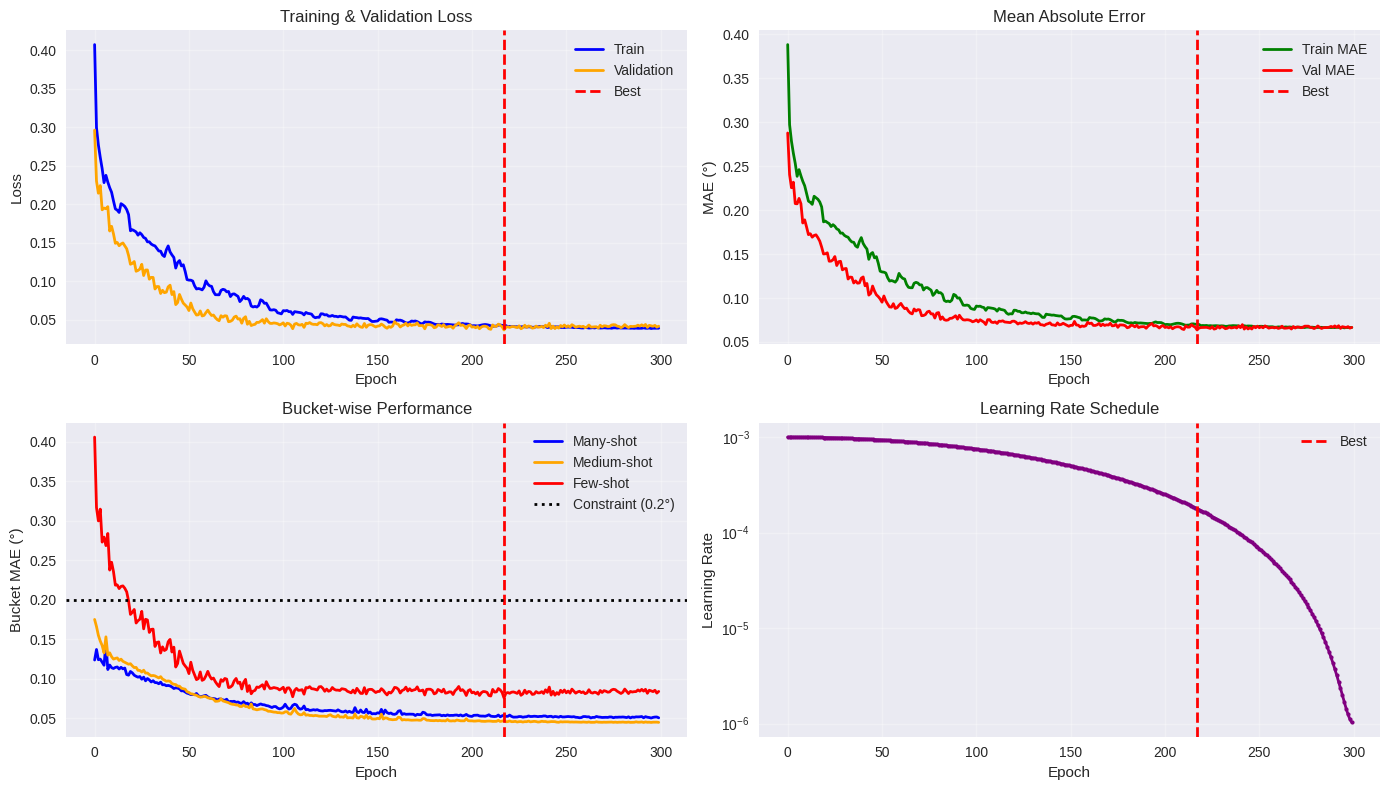


TRAINING SUMMARY - LSTM
Best Epoch: 218/300
Best Val Loss: 0.03686
Best Val MAE: 0.06367
Final LR: 0.000001
Early Stop: No

Bucket MAE at Best Epoch:
  Many-shot:   0.0539°
  Medium-shot: 0.0469°
  Few-shot:    0.0758°



In [15]:
# ============================================================================
# TRAINING VISUALIZATION
# ============================================================================

fig, axes = plt.subplots(2, 2, figsize=CONFIG['FIG_SIZE'])

# Loss curves
axes[0, 0].plot(train_curve, label="Train", color='blue', linewidth=2)
axes[0, 0].plot(val_curve, label="Validation", color='orange', linewidth=2)
axes[0, 0].axvline(x=best_epoch, color='red', linestyle='--', linewidth=2, label='Best')
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].set_title("Training & Validation Loss")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# MAE curves
axes[0, 1].plot(train_mae_curve, label="Train MAE", color='green', linewidth=2)
axes[0, 1].plot(val_mae_curve, label="Val MAE", color='red', linewidth=2)
axes[0, 1].axvline(x=best_epoch, color='red', linestyle='--', linewidth=2, label='Best')
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("MAE (°)")
axes[0, 1].set_title("Mean Absolute Error")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Bucket MAE evolution
axes[1, 0].plot(bucket_many, label="Many-shot", color='blue', linewidth=2)
axes[1, 0].plot(bucket_medium, label="Medium-shot", color='orange', linewidth=2)
axes[1, 0].plot(bucket_few, label="Few-shot", color='red', linewidth=2)
axes[1, 0].axvline(x=best_epoch, color='red', linestyle='--', linewidth=2)
axes[1, 0].axhline(y=CONFIG['MANY_SHOT_CONSTRAINT'], color='black', linestyle=':', 
                   linewidth=2, label=f"Constraint ({CONFIG['MANY_SHOT_CONSTRAINT']}°)")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Bucket MAE (°)")
axes[1, 0].set_title("Bucket-wise Performance")
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Learning rate schedule
axes[1, 1].plot(learning_rate_curve, color='purple', linewidth=2, marker='o', markersize=3)
axes[1, 1].axvline(x=best_epoch, color='red', linestyle='--', linewidth=2, label='Best')
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Learning Rate")
axes[1, 1].set_title("Learning Rate Schedule")
axes[1, 1].set_yscale('log')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Training summary
print(f"\n{'='*80}")
print(f"TRAINING SUMMARY - {CONFIG['MODEL_TYPE']}")
print(f"{'='*80}")
print(f"Best Epoch: {best_epoch + 1}/{len(train_curve)}")
print(f"Best Val Loss: {min(val_curve):.5f}")
print(f"Best Val MAE: {min(val_mae_curve):.5f}")
print(f"Final LR: {learning_rate_curve[-1]:.6f}")
print(f"Early Stop: {'Yes' if len(train_curve) < CONFIG['NUM_EPOCHS'] else 'No'}")
print(f"\nBucket MAE at Best Epoch:")
print(f"  Many-shot:   {bucket_many[best_epoch]:.4f}°")
print(f"  Medium-shot: {bucket_medium[best_epoch]:.4f}°")
print(f"  Few-shot:    {bucket_few[best_epoch]:.4f}°")
print(f"{'='*80}\n")

In [16]:
# ============================================================================
# GENERATE PREDICTIONS
# ============================================================================

print(f"\nLoading test data from: {CONFIG['TEST_PATH']}")
test_dataloader = load_test_data(
    test_path=CONFIG['TEST_PATH'],
    batchsize=CONFIG['BATCH_SIZE'],
    pipeline=pipeline,
    load_anonymized_data=True,
)

print(f"Generating predictions...")
model.eval()
test_preds = []

with torch.no_grad():
    for x, y in test_dataloader:
        x = x.to(device)
        pred = model(x)
        test_preds.append(pred.cpu().numpy())

test_preds = np.concatenate(test_preds).flatten()

print(f"\n✓ Generated {len(test_preds)} predictions")
print(f"  Range: [{test_preds.min():.2f}°, {test_preds.max():.2f}°]")
print(f"  Mean: {test_preds.mean():.3f}° | Std: {test_preds.std():.3f}°")

# Sanity checks
assert len(test_preds) > 0, "No predictions generated!"
assert not np.isnan(test_preds).any(), "NaN values in predictions!"
assert not np.isinf(test_preds).any(), "Inf values in predictions!"
print("✓ Predictions passed sanity checks")


Loading test data from: ../datasets_challenge/test
../datasets_challenge/test/test_part_001.csv
../datasets_challenge/test/test_part_002.csv
../datasets_challenge/test/test_part_003.csv
../datasets_challenge/test/test_part_004.csv
../datasets_challenge/test/test_part_005.csv
../datasets_challenge/test/test_part_006.csv
../datasets_challenge/test/test_part_007.csv
../datasets_challenge/test/test_part_008.csv
../datasets_challenge/test/test_part_009.csv
../datasets_challenge/test/test_part_010.csv
../datasets_challenge/test/test_part_011.csv
Generating predictions...

✓ Generated 49328 predictions
  Range: [-6.97°, 9.23°]
  Mean: 0.012° | Std: 1.384°
✓ Predictions passed sanity checks


In [17]:


test_ground_truths = []
with torch.no_grad():
    for x, y in test_dataloader:
        test_ground_truths.append(y.numpy())
test_ground_truths = np.concatenate(test_ground_truths)

fig = go.Figure()
fig.add_trace(go.Scatter(y=test_ground_truths, mode='lines', name='Placeholder (zeros)', 
                         line=dict(color='blue', width=1)))
fig.add_trace(go.Scatter(y=test_preds.flatten(), mode='lines', name='Predictions', 
                         line=dict(color='red', width=1), opacity=0.7))
fig.update_layout(
    title='Test Set Predictions',
    xaxis_title='Sample Index',
    yaxis_title='Sideslip Angle (°)',
    width=CONFIG['PLOTLY_WIDTH'],
    height=CONFIG['PLOTLY_HEIGHT']
)
fig.show()

In [18]:


y_pred = pd.DataFrame({
    "id": range(len(test_preds)),
    "predicted_sideslip": test_preds
})

y_pred.to_csv(CONFIG['SUBMISSION_CSV'], index=False)

print(f"✅ Predictions saved to: {CONFIG['SUBMISSION_CSV']}")
print(f"   Total samples: {len(test_preds)}")
print(f"   Ready for submission!")

✅ Predictions saved to: predictions.csv
   Total samples: 49328
   Ready for submission!


In [19]:
# ============================================================================
# EVALUATE TRAINING PREDICTIONS WITH CHALLENGE METRIC
# ============================================================================

print("Evaluating training predictions with official challenge metric...\n")

# Create ground truth dataframe
gt_df = pd.DataFrame({"ground_truth_sideslip": ground_truths}, dtype=np.float64)
gt_df["id"] = range(len(ground_truths))
gt_df["band"] = gt_df["ground_truth_sideslip"].round(1).map(shot_band_mapping).fillna("unknown")

# Create predictions dataframe
preds_df = pd.DataFrame({"id": range(len(preds)), "predicted_sideslip": preds})

# Calculate score
score_result = score(gt_df, preds_df, row_id_column_name="id")

print(f"\n{'='*80}")
print(f"CHALLENGE METRIC RESULTS (Training Data)")
print(f"{'='*80}")
print(f"Overall Score: {score_result}")
print(f"\nBand Distribution:")
print(gt_df["band"].value_counts())
print(f"{'='*80}\n")

Evaluating training predictions with official challenge metric...


CHALLENGE METRIC RESULTS (Training Data)
Overall Score: band
few       0.250783
many      0.043566
medium    0.153079
Name: L1, dtype: float64

Band Distribution:
band
many      124956
medium      9521
few         2603
Name: count, dtype: int64

